# Student Stress Level Prediction using Machine Learning
**ML Lab Mini Project** | Model: Logistic Regression (compared with Random Forest)

Target: Stress_Level → 0 = Low, 1 = Medium, 2 = High

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [2]:
data = {
  "Sleep_Hours": [7.1,8.5,7.9,5.1,5.5,8.4,4.0,8.1,8.0,6.3,5.5,5.4,5.3,6.2,6.5,6.8,9.0,8.0,7.1,8.9,5.1,4.8,7.1,4.2,4.2,6.6,6.3,8.6,7.1,6.6,6.5,5.2,4.1,5.0,7.5,5.0,5.8,4.0,8.2,4.8,5.3,8.4,6.5,8.2,7.2,7.7,4.5,6.7,6.5,8.4,5.8,7.0,4.3,5.9,5.6,4.8,8.1,5.9,8.9,6.9],
  "Study_Hours": [5.8,6.1,6.4,2.2,4.5,2.9,4.2,1.8,8.7,2.7,6.4,3.4,8.0,6.3,2.1,7.8,8.6,8.2,5.6,2.2,2.5,8.4,5.4,2.4,8.1,6.1,5.6,4.0,4.3,2.9,1.3,8.0,4.7,5.4,3.6,7.0,1.2,4.0,1.2,2.0,8.7,6.3,4.4,5.2,8.0,3.8,5.7,6.5,3.8,5.2,7.1,8.3,2.2,8.5,1.0,7.0,7.5,2.1,4.4,7.5],
  "Screen_Time_Hours": [1.1,6.7,8.1,5.6,7.5,3.0,2.8,4.3,2.6,4.1,9.5,6.2,4.1,3.4,9.6,5.0,9.8,5.6,5.7,9.1,7.7,6.2,4.8,8.9,4.7,9.3,1.6,4.9,5.7,9.6,3.3,8.3,7.1,7.5,6.7,9.7,4.0,4.6,2.8,1.5,2.9,9.2,8.6,2.0,6.4,5.3,6.4,6.9,3.8,9.7,5.2,6.7,6.7,2.7,1.6,4.7,7.9,8.3,7.6,2.0],
  "Physical_Activity_Min": [82,82,62,72,66,78,80,47,73,82,26,4,15,2,39,1,23,22,63,22,85,16,87,51,21,3,27,53,9,14,10,61,7,1,41,27,51,84,77,48,57,73,39,59,19,54,21,17,68,51,33,3,21,72,42,86,81,76,1,4],
  "Pending_Assignments": [5,3,8,3,1,1,3,6,1,7,3,3,6,8,4,7,3,1,8,7,7,8,4,1,5,5,3,6,2,6,7,0,4,6,0,6,9,8,6,8,3,3,0,7,3,8,4,8,1,1,3,0,4,6,6,2,1,5,6,9],
  "Stress_Level": [0,0,2,0,1,0,1,0,0,0,2,1,2,2,1,2,1,0,1,1,2,2,0,1,2,2,0,0,0,2,1,1,2,2,0,2,2,2,0,1,1,0,0,0,1,1,2,2,0,0,2,1,2,1,1,1,0,1,1,2]
}

df = pd.DataFrame(data)
df.head()


,Sleep_Hours,Study_Hours,Screen_Time_Hours,Physical_Activity_Min,Pending_Assignments,Stress_Level
0,7.1,5.8,1.1,82,5,0
1,8.5,6.1,6.7,82,3,0
2,7.9,6.4,8.1,62,8,2
3,5.1,2.2,5.6,72,3,0
4,5.5,4.5,7.5,66,1,1


In [3]:
df.shape

(60, 6)

In [4]:
df.isnull().sum()

Sleep_Hours              0
Study_Hours              0
Screen_Time_Hours        0
Physical_Activity_Min    0
Pending_Assignments      0
Stress_Level             0
dtype: int64

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Sleep_Hours            60 non-null     float64
 1   Study_Hours            60 non-null     float64
 2   Screen_Time_Hours      60 non-null     float64
 3   Physical_Activity_Min  60 non-null     int64  
 4   Pending_Assignments    60 non-null     int64  
 5   Stress_Level           60 non-null     int64  
dtypes: float64(3), int64(3)
memory usage: 2.9 KB


In [6]:
df.describe()

,Sleep_Hours,Study_Hours,Screen_Time_Hours,Physical_Activity_Min,Pending_Assignments,Stress_Level
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,6.448333,5.086667,5.788333,43.183333,4.483333,1.000000
std,1.451883,2.347986,2.525403,28.740506,2.658480,0.823387
min,4.000000,1.000000,1.100000,1.000000,0.000000,0.000000
25%,5.275000,2.900000,3.950000,18.500000,3.000000,0.000000
50%,6.500000,5.300000,5.700000,44.500000,4.500000,1.000000
75%,7.750000,7.025000,7.750000,72.000000,7.000000,2.000000
max,9.000000,8.700000,9.800000,87.000000,9.000000,2.000000


In [7]:
df["Stress_Level"].value_counts().sort_index()

Stress_Level
0    20
1    20
2    20
Name: count, dtype: int64

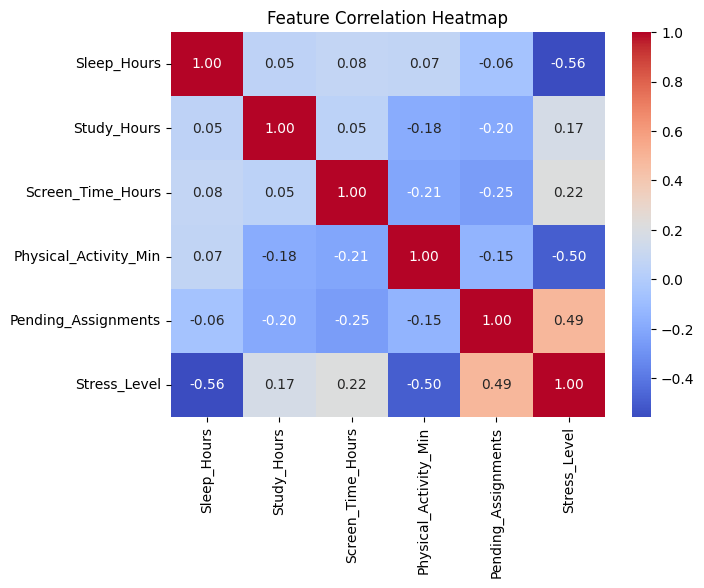

In [8]:
plt.figure(figsize=(7,5))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()


In [9]:
X = df[["Sleep_Hours", "Study_Hours", "Screen_Time_Hours", "Physical_Activity_Min", "Pending_Assignments"]]
y = df["Stress_Level"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)


Feature shape: (60, 5)
Target shape: (60,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (48, 5)
Testing data shape: (12, 5)


In [11]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)


In [12]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)
print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [13]:
y_pred = model.predict(X_test_s)

print("Actual Values:")
print(y_test.values)
print("\nPredicted Values:")
print(y_pred)


Actual Values:
[0 2 1 1 2 0 2 0 1 1 2 0]

Predicted Values:
[0 1 0 1 2 0 2 0 0 0 2 0]


In [14]:
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", round(acc, 2))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Low", "Medium", "High"], zero_division=0))


Accuracy: 0.67

Classification Report:
              precision    recall  f1-score   support

         Low       0.57      1.00      0.73         4
      Medium       0.50      0.25      0.33         4
        High       1.00      0.75      0.86         4

    accuracy                           0.67        12
   macro avg       0.69      0.67      0.64        12
weighted avg       0.69      0.67      0.64        12



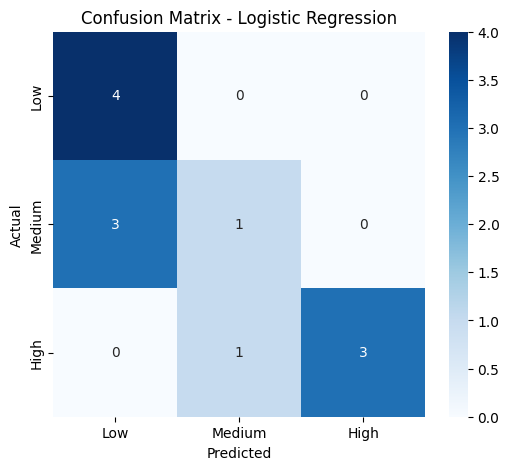

In [15]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Low", "Medium", "High"],
            yticklabels=["Low", "Medium", "High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


In [16]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_acc = accuracy_score(y_test, rf.predict(X_test))

print("Logistic Regression Accuracy:", round(acc, 2))
print("Random Forest Accuracy      :", round(rf_acc, 2))


Logistic Regression Accuracy: 0.67
Random Forest Accuracy      : 0.67


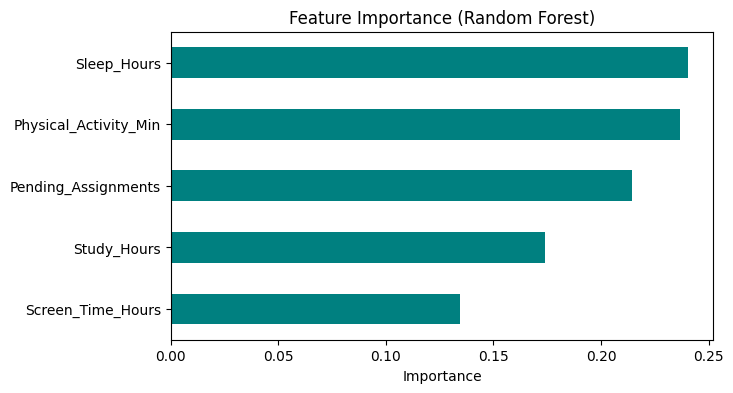

In [17]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
importance.plot(kind="barh", figsize=(7,4), color="teal")
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance")
plt.show()


In [18]:
new_student = pd.DataFrame({
   "Sleep_Hours": [5.0],
   "Study_Hours": [7.0],
   "Screen_Time_Hours": [8.0],
   "Physical_Activity_Min": [10],
   "Pending_Assignments": [6]
})

labels = {0: "Low", 1: "Medium", 2: "High"}
pred_class = model.predict(scaler.transform(new_student))[0]
print("Predicted Stress Level:", labels[pred_class])


Predicted Stress Level: High


In [19]:
print("========================================")
print("STUDENT STRESS LEVEL PREDICTION USING ML")
print("========================================")
print("\nModel: Logistic Regression")
print("Accuracy :", round(acc, 2))
print("Random Forest Accuracy :", round(rf_acc, 2))
print("\nNew Student Details:")
print("Sleep Hours        : 5.0")
print("Study Hours        : 7.0")
print("Screen Time        : 8.0 hrs")
print("Physical Activity  : 10 min")
print("Pending Assignments: 6")
print("\nPredicted Stress Level :", labels[pred_class])
print("========================================")


STUDENT STRESS LEVEL PREDICTION USING ML

Model: Logistic Regression
Accuracy : 0.67
Random Forest Accuracy : 0.67

New Student Details:
Sleep Hours        : 5.0
Study Hours        : 7.0
Screen Time        : 8.0 hrs
Physical Activity  : 10 min
Pending Assignments: 6

Predicted Stress Level : High
